# Avance 3. Baseline — Equipo 38

## Nota de revisión y atribución
**Esta corrección y revisión metodológica la realiza el Equipo 38 (16 de octubre de 2026).**
El notebook original de clasificación de galaxias con anillos fue elaborado previamente por otro equipo. El Equipo 38 conserva ese trabajo como punto de partida y corrige la validación, la interpretación y la coherencia de sus conclusiones; no se atribuye la autoría del desarrollo original.

- **Clase 0:** galaxia sin anillo.
- **Clase 1:** galaxia con anillo, con referencia a anillo interno. Verificar esta definición con el origen de las etiquetas.
- **Modelo de referencia:** Random Forest sobre características tabulares.
- **Comparadores simples:** Dummy estratificado y Dummy mayoritario.
- **Métrica principal:** F1-macro; complementarias: Average Precision (AP), ROC-AUC, precisión y recall de anillos.

**Estado:** baseline ejecutado con el CSV real; esta revisión conserva las salidas observadas y amplía su análisis. La secuencia guardada contiene 17 celdas de código, con conteos consecutivos y sin errores registrados. Esto evidencia ejecución ordenada, pero no certifica un kernel limpio. Antes de publicar, ejecutar Restart & Run All y guardar la libreta.

**Alcance:** clasificación binaria de anillos internos frente a ausencia de anillo. La correspondencia exacta entre las etiquetas y el catálogo de origen requiere validación documental. Esta libreta cubre el objetivo de anillos, no otros objetivos de GalMorphAI.

**Objetivo del baseline:** establecer una referencia reproducible sobre los atributos disponibles, medir si aporta mejora observada frente a predicciones triviales, identificar limitaciones y dejar criterios comparables para modelos posteriores. Un baseline útil para diagnóstico no equivale a un detector listo para uso científico.

In [1]:
from pathlib import Path
import sys
import platform
import sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (f1_score, roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, learning_curve

RANDOM_STATE = 42
# Opcional: indicar una ruta explícita; con None se busca desde cwd y sus ancestros.
DATA_PATH_OVERRIDE = None
DATA_RELATIVE = Path('feature_engineering/output/feature_engineered_dataset.csv')
print(f'Python {platform.python_version()} | scikit-learn {sklearn.__version__} | pandas {pd.__version__}')

Python 3.14.5 | scikit-learn 1.8.0 | pandas 3.0.3


### Carga de datos y procesamiento

In [2]:
if DATA_PATH_OVERRIDE is not None:
    DATA_PATH = Path(DATA_PATH_OVERRIDE).expanduser().resolve()
else:
    candidates = [root / DATA_RELATIVE for root in (Path.cwd(), *Path.cwd().parents)]
    DATA_PATH = next((path for path in candidates if path.is_file()), None)
    if DATA_PATH is None:
        raise FileNotFoundError(
            'No se encontró feature_engineering/output/feature_engineered_dataset.csv. '
            'Abra Jupyter dentro del repositorio o configure DATA_PATH_OVERRIDE.')
if not DATA_PATH.is_file():
    raise FileNotFoundError(DATA_PATH)
df = pd.read_csv(DATA_PATH)
required = {'name', 'label', 'split'}
if not required.issubset(df.columns):
    raise ValueError(f'Faltan columnas: {required - set(df.columns)}')
if df[list(required)].isna().any().any():
    raise ValueError('Hay identificadores, etiquetas o particiones nulas.')
if set(df['label'].unique()) != {0, 1}:
    raise ValueError('label debe contener exactamente las clases 0 y 1.')
if set(df['split'].unique()) != {'train', 'test'}:
    raise ValueError('split debe contener exactamente train y test.')
# Corrección del Equipo 38: una observación por identificador.
filas_antes = len(df)
df = df.drop_duplicates().copy()
print(f'Filas idénticas eliminadas: {filas_antes - len(df)}')

repetidos = df.loc[df['name'].duplicated(keep=False)].copy()
if not repetidos.empty:
    resumen_duplicados = repetidos.groupby('name').agg(
        registros=('name', 'size'),
        particiones=('split', 'nunique'),
        etiquetas=('label', 'nunique')
    )
    display(resumen_duplicados)
    if (resumen_duplicados['particiones'] > 1).any():
        raise ValueError(
            'Una misma galaxia aparece en train y test. Corregir la partición '
            'por identificador en el origen; no deduplicar entre particiones.')
    if (resumen_duplicados['etiquetas'] > 1).any():
        raise ValueError('Un identificador tiene etiquetas contradictorias. Revisar el origen.')
    if 'source' in df and (repetidos.groupby('name')['source'].nunique(dropna=False) > 1).any():
        raise ValueError('Un identificador aparece con fuentes distintas. Revisar su identidad antes de consolidar.')

    # Regla de referencia: mayor completitud; empate por orden original del CSV.
    # No utiliza valores de label ni el desempeño del modelo para elegir la fila.
    metadata_dedup = {'name', 'source', 'anillos', 'label', 'split',
                      'has_fits', 'has_image_features', 'fits_path'}
    cols_completitud = [col for col in df.select_dtypes(include='number').columns
                        if col not in metadata_dedup]
    completitud = df[cols_completitud].notna().sum(axis=1)
    ranking = pd.DataFrame({
        'name': df['name'],
        'no_nulas': completitud,
        'orden_csv': np.arange(len(df))
    }, index=df.index)
    indices_elegidos = (ranking.sort_values(
        ['no_nulas', 'orden_csv'], ascending=[False, True], kind='stable')
        .drop_duplicates('name', keep='first').index)
    auditoria_duplicados = repetidos[['name', 'label', 'split']].copy()
    auditoria_duplicados['fila_csv_datos'] = ranking.loc[repetidos.index, 'orden_csv'] + 1
    auditoria_duplicados['caracteristicas_no_nulas'] = completitud.loc[repetidos.index]
    auditoria_duplicados['decision'] = np.where(
        auditoria_duplicados.index.isin(indices_elegidos), 'CONSERVAR', 'DESCARTAR')
    display(auditoria_duplicados)
    descartadas = len(df) - len(indices_elegidos)
    df = df.loc[df.index.isin(indices_elegidos)].copy()
    print(f'Filas adicionales consolidadas por identificador: {descartadas}')
    print('Empates de completitud: se conserva la primera fila del CSV; no implica mayor precisión física.')
assert not df['name'].duplicated().any()
print(f'Datos: {DATA_PATH}\nShape: {df.shape}')
display(df.head(2))

Filas idénticas eliminadas: 0


,registros,particiones,etiquetas
name,,,
1237678596462739488,2,1,1


,name,label,split,fila_csv_datos,caracteristicas_no_nulas,decision
6443,1237678596462739488,0,train,6444,27,CONSERVAR
6518,1237678596462739488,0,train,6519,27,DESCARTAR


Filas adicionales consolidadas por identificador: 1
Empates de completitud: se conserva la primera fila del CSV; no implica mayor precisión física.
Datos: c:\Users\VACORTES\Documents\GalMorphAI\RingGalaxiesAnalysis\feature_engineering\output\feature_engineered_dataset.csv
Shape: (8407, 94)


,name,source,anillos,label,split,has_fits,has_image_features,fits_path,objra,objdec,...,lupton_lum_concentration_20_std,lupton_lum_outer_to_inner_flux_std,lupton_lum_peak_radius_norm_std,lupton_lum_ring_contrast_std,lupton_lum_asymmetry_180_std,pca_1,pca_2,pca_3,fa_1,fa_2
0,1237648721210769659,sdss,0,0,train,1,1,C:\Users\VACORTES\Documents\GalMorphAI\RingGal...,134.44717,-0.199973,...,0.641513,-0.503832,0.334257,0.446965,-0.392619,1.487783,-0.058581,0.512083,1.069905,0.182063
1,1237648705657307354,sdss,0,0,train,1,1,C:\Users\VACORTES\Documents\GalMorphAI\RingGal...,198.23356,0.941188,...,-0.429497,-0.134377,1.567480,-0.644007,0.016431,-1.126702,-0.859460,0.578559,-0.802575,-0.025781


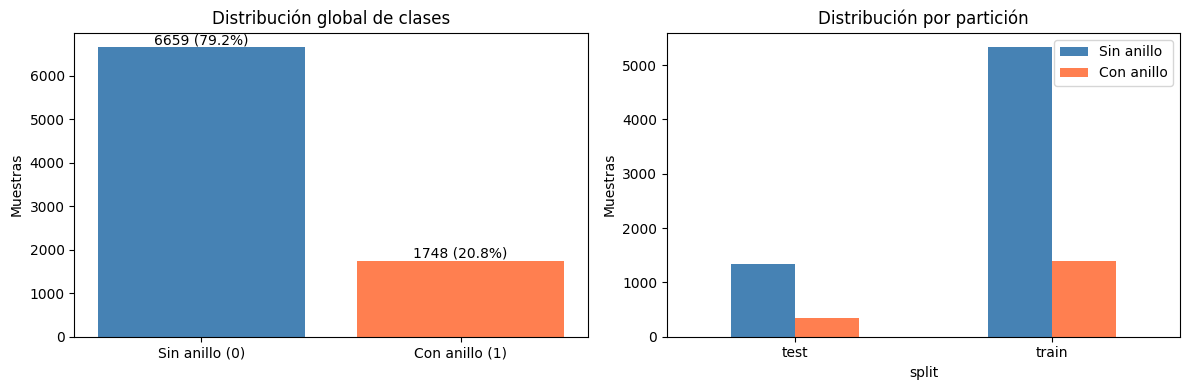

Razón sin anillo/con anillo: 3.81:1


label,0,1
split,,
test,1333,349
train,5326,1399


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df['label'].value_counts().reindex([0, 1], fill_value=0)
axes[0].bar(['Sin anillo (0)', 'Con anillo (1)'], counts.values, color=['steelblue', 'coral'])
axes[0].set_title('Distribución global de clases')
axes[0].set_ylabel('Muestras')
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f'{v} ({v/len(df):.1%})', ha='center', va='bottom')
split_counts = df.groupby(['split', 'label']).size().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
if (split_counts == 0).any().any():
    raise ValueError('Cada partición debe contener ambas clases.')
split_counts.plot(kind='bar', ax=axes[1], color=['steelblue', 'coral'], rot=0)
axes[1].set_title('Distribución por partición')
axes[1].set_ylabel('Muestras')
axes[1].legend(['Sin anillo', 'Con anillo'])
plt.tight_layout()
plt.show()
print(f'Razón sin anillo/con anillo: {counts[0]/counts[1]:.2f}:1')
display(split_counts)

In [4]:
META_COLS = ['name', 'source', 'anillos', 'label', 'split', 'has_fits', 'has_image_features', 'fits_path']
FEATURE_COLS = [col for col in df.columns if col not in META_COLS]
if not FEATURE_COLS:
    raise ValueError('No hay características predictoras.')
non_numeric = df[FEATURE_COLS].select_dtypes(exclude='number').columns.tolist()
if non_numeric:
    raise ValueError(f'Características no numéricas: {non_numeric}')
if np.isinf(df[FEATURE_COLS].to_numpy(dtype=float)).any():
    raise ValueError('Hay valores infinitos. Revisar ingeniería de características.')
print(f'Características candidatas: {len(FEATURE_COLS)}')
print(f'Registros con algún nulo: {df[FEATURE_COLS].isna().any(axis=1).sum()} de {len(df)}')
if 'has_fits' in df:
    print(f'Registros marcados sin FITS: {(df["has_fits"] == 0).sum()}')
missing_report = pd.DataFrame({
    'nulos': df[FEATURE_COLS].isna().sum(),
    'porcentaje_nulos': 100 * df[FEATURE_COLS].isna().mean()
}).sort_values('nulos', ascending=False)
display(missing_report.head(20))

Características candidatas: 86
Registros con algún nulo: 8204 de 8407
Registros marcados sin FITS: 8204


,nulos,porcentaje_nulos
img_r_log_p99_pos,8204,97.585346
img_g_log_flux_pos,8204,97.585346
img_z_log_flux_pos,8204,97.585346
img_z_log_p99_pos,8204,97.585346
img_gr_log_flux_ratio,8204,97.585346
img_r_log_flux_pos,8204,97.585346
img_g_log_p99_pos,8204,97.585346
lupton_lum_center_mean,8204,97.585346
lupton_green_dominance,8204,97.585346
lupton_red_dominance,8204,97.585346


### Preparación y límites de la auditoría

La imputación por mediana se ajusta solo con entrenamiento. Dentro de validación cruzada se vuelve a ajustar en cada fold mediante un `Pipeline`. No se asume que imputar sea neutral: la ausencia de datos puede estar relacionada con la clase o la fuente.

Se excluyen metadatos y etiquetas alternativas como `anillos`. Las columnas completamente vacías en entrenamiento se eliminan sin consultar prueba.

**Pendiente de verificar en la ingeniería de características:** escaladores, PCA, análisis factorial y límites de bins aprendidos deben ajustarse solo con entrenamiento; en validación cruzada, dentro de cada fold. Este CSV ya transformado no permite certificarlo. El pipeline de esta libreta corrige la imputación, pero no puede revertir una posible fuga previa. También debe comprobarse que las etiquetas no deriven de las propias características y que imágenes repetidas con identificadores distintos no crucen las particiones.

**Revisión de duplicados por el Equipo 38:** las capturas del CSV mostraron dos registros del identificador `1237678596462739488`, ambos de SDSS, clase 0 y entrenamiento, con diferencias en coordenadas, redshift y transformaciones derivadas. Son observaciones repetidas del identificador, no filas idénticas. Se conserva una sola fila por identificador para evitar darle peso doble o repartir sus observaciones entre folds.

La regla se fija antes de entrenar: eliminar filas exactas; para identificadores repetidos con la misma etiqueta, partición y fuente, elegir la fila con más características numéricas no nulas (excluidos metadatos). Si empatan, conservar la primera según el orden del CSV. La auditoría muestra la decisión por fila. Esta regla es reproducible para el mismo archivo y no determina qué medición es científicamente superior; no se promedian columnas ya transformadas, pues podrían perder coherencia. Una selección física más informada requeriría indicadores de calidad del catálogo original. Si hay etiquetas, particiones o fuentes contradictorias, la libreta se detiene para revisar el origen.

La distribución y las métricas se calculan después de consolidar registros. Las transformaciones aprendidas previamente en el CSV aún requieren auditoría y, cuando corresponda, regeneración después de depurar y separar los datos.

### Cobertura real de información visual y efecto sobre el alcance

Después de consolidar el identificador repetido quedan **8,407 galaxias**. La ejecución reporta **8,204 sin FITS (97.59%)** y solo **203 marcadas con FITS (2.41%)**. Las columnas de imagen mostradas en el diagnóstico tienen también 8,204 valores nulos. La disponibilidad de un FITS no certifica por sí sola una extracción correcta; deben revisarse los indicadores y resultados de extracción.

La imputación mantiene todas las galaxias en el experimento y evita entrenar únicamente sobre un subconjunto de imágenes que podría estar sesgado. Sin embargo, sustituye la información visual ausente por valores constantes aprendidos en entrenamiento: no reconstruye concentración, asimetría ni contraste radial propios de cada objeto. Esto limita la capacidad de evaluar el valor predictivo de las características morfológicas.

Por ello, el resultado debe describirse como un **baseline tabular con cobertura visual muy limitada**. La baja importancia de una variable de imagen en esta ejecución no permite descartar su utilidad si se recuperan mediciones válidas. Tampoco demuestra que la ausencia de imágenes explique por sí sola todo el desempeño. La primera acción de mejora es auditar rutas y extracción para distinguir archivos inexistentes de archivos disponibles que no fueron procesados.

Los identificadores no se incluyen como predictores. La auditoría retuvo la fila 6444 del CSV y descartó la 6519 para el identificador repetido, ambas con 27 características numéricas disponibles, misma etiqueta, fuente y partición. La selección se hizo por la regla de desempate documentada, sin consultar la puntuación del modelo.


In [5]:
train_df = df.loc[df['split'] == 'train'].copy()
test_df = df.loc[df['split'] == 'test'].copy()
empty_train = [col for col in FEATURE_COLS if train_df[col].isna().all()]
FEATURE_COLS = [col for col in FEATURE_COLS if col not in empty_train]
if not FEATURE_COLS:
    raise ValueError('Todas las características están vacías en entrenamiento.')
print(f'Columnas excluidas por estar vacías en train: {empty_train}')
X_train = train_df[FEATURE_COLS].copy()
X_test = test_df[FEATURE_COLS].copy()
y_train = train_df['label'].to_numpy(dtype=int)
y_test = test_df['label'].to_numpy(dtype=int)
print(f'Train: {X_train.shape} | anillos: {y_train.mean():.1%}')
print(f'Test: {X_test.shape} | anillos: {y_test.mean():.1%}')
if min(np.bincount(y_train)) < 5:
    raise ValueError('Se requieren al menos 5 ejemplos de cada clase para CV=5.')

Columnas excluidas por estar vacías en train: []
Train: (6725, 86) | anillos: 20.8%
Test: (1682, 86) | anillos: 20.7%


### Comparadores simples

El Dummy estratificado genera predicciones aleatorias según la proporción de clases de entrenamiento; es una referencia estocástica, no un piso universal. Se agrega el Dummy mayoritario para mostrar cómo una accuracy alta puede coexistir con recall nulo de anillos. Una ejecución del Dummy no prueba significancia estadística.

In [6]:
dummy_results = []
for strategy in ['stratified', 'most_frequent']:
    dummy = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE)
    dummy.fit(X_train, y_train)
    pred = dummy.predict(X_test)
    prob = dummy.predict_proba(X_test)[:, list(dummy.classes_).index(1)]
    dummy_results.append({'Modelo': f'Dummy {strategy}',
        'F1-macro': f1_score(y_test, pred, average='macro', zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, prob),
        'AP': average_precision_score(y_test, prob)})
    print(f'\nDummy {strategy}')
    print(classification_report(y_test, pred, labels=[0, 1], target_names=['Sin anillo', 'Con anillo'], zero_division=0))
display(pd.DataFrame(dummy_results))


Dummy stratified
              precision    recall  f1-score   support

  Sin anillo       0.79      0.78      0.79      1333
  Con anillo       0.21      0.22      0.21       349

    accuracy                           0.67      1682
   macro avg       0.50      0.50      0.50      1682
weighted avg       0.67      0.67      0.67      1682


Dummy most_frequent
              precision    recall  f1-score   support

  Sin anillo       0.79      1.00      0.88      1333
  Con anillo       0.00      0.00      0.00       349

    accuracy                           0.79      1682
   macro avg       0.40      0.50      0.44      1682
weighted avg       0.63      0.79      0.70      1682



,Modelo,F1-macro,ROC-AUC,AP
0,Dummy stratified,0.500027,0.500105,0.207526
1,Dummy most_frequent,0.442123,0.500000,0.207491


### Justificación de Random Forest

Se conserva Random Forest como baseline tabular porque captura relaciones no lineales e interacciones sin requerir escalado. Permite ponderar clases mediante `class_weight='balanced'`, lo que resulta pertinente ante el desbalance observado, aunque no garantiza mayor F1 ni recall.

El ensamble tolera predictores redundantes, pero la colinealidad dificulta interpretar su importancia. Una regresión logística regularizada también sería un comparador válido y más simple: no se descarta por supuestamente colapsar ante correlación.

Se utilizan 300 árboles para estabilizar el ensamble, `max_depth=10` y `min_samples_leaf=5` como restricciones iniciales de complejidad. Estos valores son decisiones de referencia, no parámetros óptimos demostrados. Se conservan sin optimización sobre prueba. El número real de características se imprime desde los datos.

El modelo utiliza resúmenes numéricos; no aprende directamente la geometría completa de los píxeles. Compararlo posteriormente con modelos de imagen permitirá evaluar esa limitación, sin anticipar su rendimiento.

### Comparación razonada de alternativas

| Alternativa | Papel en este problema | Motivo de la decisión |
|---|---|---|
| Dummy mayoritario y estratificado | Referencias sin aprendizaje de la relación entre atributos y etiqueta | Se ejecutan para comprobar que el modelo aporte algo frente a reglas triviales. |
| Regresión logística regularizada | Baseline lineal válido y simple | Sería un comparador adicional pertinente; no se ejecutó y no se afirma que su rendimiento sea inferior. Requeriría especificar preprocesamiento y regularización. |
| Random Forest | Referencia tabular capaz de representar interacciones y límites no lineales | Se conserva el desarrollo original y se fija una configuración reproducible, con ponderación de clases y límites de complejidad. |
| Modelo entrenado con imágenes | Evaluación posterior de la estructura visual | Requiere imágenes utilizables y un protocolo propio. No se atribuyen resultados esperados sin experimentos. |

Random Forest es una referencia inicial de complejidad moderada, no el modelo más simple posible ni un algoritmo óptimo demostrado. La elección permite evaluar el conjunto de atributos ya construido sin introducir una búsqueda de hiperparámetros que utilice la prueba. El pipeline de imputación y el uso de una semilla fija facilitan repetir el experimento.

**Control experimental:** en esta revisión se mantienen 300 árboles, profundidad máxima 10 y al menos 5 muestras por hoja. Los árboles permiten modelar interacciones; las restricciones buscan limitar la memorización. El sobreajuste observado indica que esas restricciones no bastaron para cerrar la brecha. Una eventual modificación se seleccionaría dentro de entrenamiento, no mediante intentos sucesivos sobre esta prueba.


In [7]:
rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('model', RandomForestClassifier(n_estimators=300, max_depth=10,
        min_samples_leaf=5, class_weight='balanced', n_jobs=-1,
        random_state=RANDOM_STATE))
])
rf.fit(X_train, y_train)
y_pred_train = rf.predict(X_train)
y_pred_test = rf.predict(X_test)
y_prob_test = rf.predict_proba(X_test)[:, list(rf.classes_).index(1)]
train_f1 = f1_score(y_train, y_pred_train, average='macro', zero_division=0)
test_f1 = f1_score(y_test, y_pred_test, average='macro', zero_division=0)
test_auc = roc_auc_score(y_test, y_prob_test)
test_ap = average_precision_score(y_test, y_prob_test)
print(classification_report(y_test, y_pred_test, labels=[0, 1], target_names=['Sin anillo', 'Con anillo'], zero_division=0))
print(f'F1-macro train: {train_f1:.4f}\nF1-macro test: {test_f1:.4f}')
print(f'ROC-AUC: {test_auc:.4f}\nAverage Precision: {test_ap:.4f}')

              precision    recall  f1-score   support

  Sin anillo       0.83      0.75      0.79      1333
  Con anillo       0.30      0.41      0.34       349

    accuracy                           0.68      1682
   macro avg       0.56      0.58      0.56      1682
weighted avg       0.72      0.68      0.69      1682

F1-macro train: 0.6975
F1-macro test: 0.5649
ROC-AUC: 0.6203
Average Precision: 0.3074


### Diagnóstico de ajuste

Se compara F1-macro en entrenamiento, validación cruzada y prueba. Una brecha positiva grande es compatible con sobreajuste; el umbral de 0.10 se usa como alerta heurística, no como prueba estadística. Una brecha pequeña no garantiza utilidad: ambas puntuaciones podrían ser bajas. Tampoco un resultado bajo en prueba demuestra que las características carezcan de información.

In [8]:
gap = train_f1 - test_f1
if gap > 0.10:
    diagnosis = 'Indicio de sobreajuste: brecha superior a la alerta heurística de 0.10.'
elif gap < -0.05:
    diagnosis = 'Prueba supera entrenamiento: revisar incertidumbre y dificultad de las particiones.'
else:
    diagnosis = 'Sin brecha grande según la alerta; revisar también el desempeño absoluto y CV.'
print(f'Train F1-macro: {train_f1:.4f}\nTest F1-macro: {test_f1:.4f}\nBrecha: {gap:.4f}')
print(diagnosis)

Train F1-macro: 0.6975
Test F1-macro: 0.5649
Brecha: 0.1326
Indicio de sobreajuste: brecha superior a la alerta heurística de 0.10.


### Curva de aprendizaje

Se utiliza el mismo pipeline y la misma configuración del baseline con validación estratificada de cinco folds y mezcla reproducible. La imputación se ajusta dentro de cada fold. Las bandas representan desviación estándar entre folds, no intervalos de confianza.

La tendencia permite explorar si aumentar datos ayuda dentro del rango observado. Una brecha persistente no demuestra que más datos nunca ayudarán. Diferencias grandes entre validación y prueba requieren investigar particiones, calidad de datos y posibles cambios de distribución antes de atribuirlas a las características.

### Interpretación de la curva de esta ejecución

El F1-macro de entrenamiento desciende aproximadamente de **0.88 a 0.72** al aumentar el tamaño usado por fold, mientras validación mejora aproximadamente de **0.54 a 0.58** y luego presenta variaciones pequeñas. Al mayor tamaño evaluado, validación alcanza **0.5847 ± 0.0110**, con brecha entrenamiento-validación de **0.1311**. En el ajuste con todo entrenamiento, F1-macro es **0.6975**, frente a **0.5649** en prueba: brecha **0.1326**.

Las dos comparaciones son consistentes con un problema de generalización. Las curvas se acercan, pero conservan separación. No se observa el patrón de puntuaciones de entrenamiento y validación igualmente altas, ni es adecuado diagnosticar exclusivamente subajuste a partir del resultado bajo en prueba. La mejora de validación con más muestras es limitada dentro del rango estudiado; no permite extrapolar una puntuación para miles de nuevas imágenes ni afirmar que agregar datos nunca ayudaría.

La validación queda aproximadamente **0.0198** por encima de prueba. Esa diferencia no es una prueba de cambio de distribución ni de significancia; corresponde a conjuntos de tamaños y composiciones distintos. La desviación entre folds no es un intervalo de confianza del resultado de prueba. Antes de aumentar complejidad se debe revisar cobertura visual, redundancia y procedencia de los atributos.


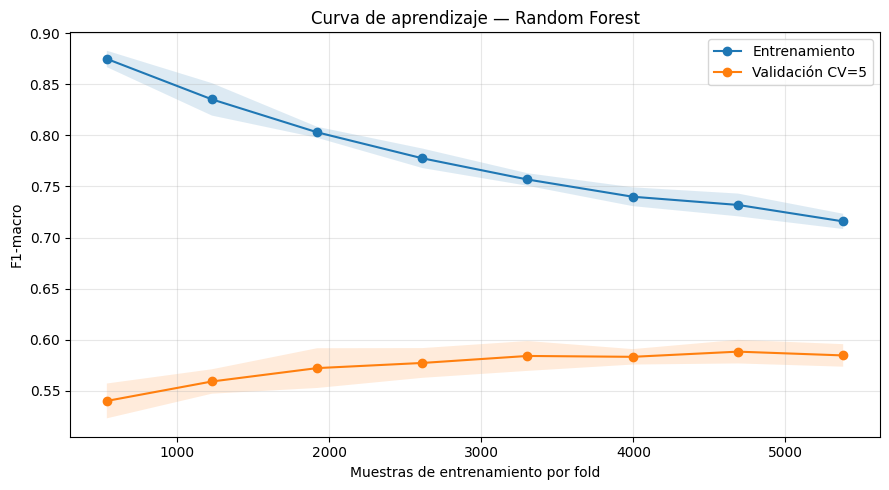

Validación al mayor tamaño evaluado: 0.5847 ± 0.0110
Brecha train-validación: 0.1311
El mayor tamaño corresponde al entrenamiento de cada fold, no al 100% del train global.


In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
lc_rf = clone(rf).set_params(model__n_jobs=1)
train_sizes, train_scores, val_scores = learning_curve(
    lc_rf, X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 8),
    scoring='f1_macro', cv=cv, shuffle=True,
    random_state=RANDOM_STATE, n_jobs=-1, error_score='raise')
tm, ts = train_scores.mean(axis=1), train_scores.std(axis=1)
vm, vs = val_scores.mean(axis=1), val_scores.std(axis=1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, tm, 'o-', label='Entrenamiento')
ax.fill_between(train_sizes, tm-ts, tm+ts, alpha=0.15)
ax.plot(train_sizes, vm, 'o-', label='Validación CV=5')
ax.fill_between(train_sizes, vm-vs, vm+vs, alpha=0.15)
ax.set(xlabel='Muestras de entrenamiento por fold', ylabel='F1-macro', title='Curva de aprendizaje — Random Forest')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Validación al mayor tamaño evaluado: {vm[-1]:.4f} ± {vs[-1]:.4f}')
print(f'Brecha train-validación: {tm[-1]-vm[-1]:.4f}')
print('El mayor tamaño corresponde al entrenamiento de cada fold, no al 100% del train global.')

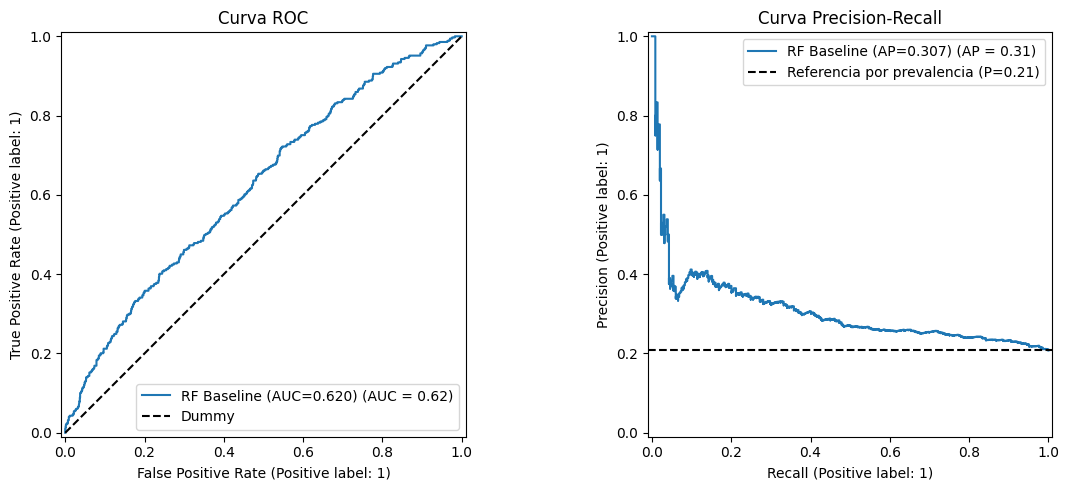

In [10]:
# Curvas ROC y Precision-Recall
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

RocCurveDisplay.from_predictions(
    y_test, y_prob_test,
    name=f'RF Baseline (AUC={test_auc:.3f})',
    ax=axes[0]
)
axes[0].plot([0, 1], [0, 1], 'k--', label='Dummy')
axes[0].set_title('Curva ROC')
axes[0].legend()

PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_test,
    name=f'RF Baseline (AP={test_ap:.3f})',
    ax=axes[1]
)
baseline_pr = y_test.mean()
axes[1].axhline(baseline_pr, color='k', linestyle='--', label=f'Referencia por prevalencia (P={baseline_pr:.2f})')
axes[1].set_title('Curva Precision-Recall')
axes[1].legend()

plt.tight_layout()
plt.show()

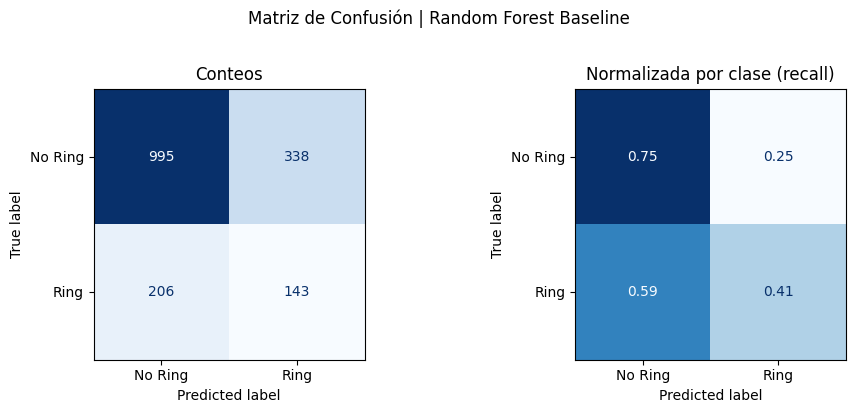

In [11]:
# Matriz de confusión
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test,
    display_labels=['No Ring', 'Ring'],
    cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title('Conteos')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test,
    display_labels=['No Ring', 'Ring'],
    normalize='true', cmap='Blues', ax=axes[1], colorbar=False
)
axes[1].set_title('Normalizada por clase (recall)')

plt.suptitle('Matriz de Confusión | Random Forest Baseline', y=1.02)
plt.tight_layout()
plt.show()

## Relevancia de características: visualización e interpretación

Se usa permutation importance, un método post hoc aplicable a cualquier modelo tabular. Mide la variación del F1-macro al permutar una columna, manteniendo el modelo entrenado. No es una medida causal ni un procedimiento wrapper de selección de variables por sí mismo.

La colinealidad puede ocultar importancia individual, porque otras variables conservan información redundante. Una media cercana a cero o negativa no prueba inutilidad ni justifica eliminar una variable automáticamente. La dispersión entre permutaciones describe sensibilidad al remuestreo de la permutación; no es un intervalo de confianza de generalización.

Aquí se inspecciona prueba para describir el modelo final. **No se utilizará este ranking para seleccionar variables ni ajustar el modelo sobre esta misma prueba.** Si se decide modificarlo, utilizar validación dentro de entrenamiento y reservar una prueba independiente para la siguiente evaluación.

### Interpretación del ranking observado

| Característica | Importancia media: caída de F1-macro | Desviación entre permutaciones | Interpretación |
|---|---:|---:|---|
| `gal_b_sin_std` | 0.004037 | 0.003549 | Encabeza el ranking, pero el efecto es pequeño y su dispersión es considerable. Corresponde a una transformación de la posición galáctica; investigar posibles patrones de selección del catálogo. |
| `z_bin_q3` | 0.002363 | 0.001516 | El modelo utiliza información asociada a un intervalo de redshift. Los límites concretos del intervalo deben consultarse en la ingeniería de características. No demuestra causalidad morfológica. |
| `z_sqrt` | 0.000907 | 0.002519 | La variación entre permutaciones es mayor que la media: contribución individual poco estable bajo este análisis. |
| `nsa_z` | 0.000544 | 0.002721 | Comparte información de redshift con otras transformaciones, lo que dificulta interpretar su contribución aislada. |

**84 de 86** variables tienen importancia media menor o igual a 0.001. Ese corte representa una caída absoluta de 0.001 de F1-macro y solo organiza la descripción; no es un umbral estadístico ni una selección de variables validada. La mayor media, 0.004037, equivale a aproximadamente **0.40 puntos porcentuales** de F1-macro.

El predominio de posición y redshift, junto con la cobertura visual de solo 2.41%, justifica investigar si el modelo está usando diferencias de selección u observación más que señales visuales de anillo. Es una hipótesis, no una conclusión causal. Los resultados cercanos a cero de varias columnas de imagen pueden relacionarse con imputación masiva, redundancia y el propio modelo; no prueban ausencia de valor científico.

Algunas variables, como `objra`, tienen importancia media negativa. En esta evaluación, permutarlas mejora el F1-macro medio; esto es compatible con dependencias poco útiles o inestables, pero no autoriza eliminarlas utilizando prueba. Las acciones futuras son inspección de correlaciones y evaluación por grupos de características dentro de validación, con una evaluación final independiente si se adoptan cambios.


In [12]:
perm_imp = permutation_importance(rf, X_test, y_test,
    n_repeats=10, scoring='f1_macro', n_jobs=-1, random_state=RANDOM_STATE)
perm_df = pd.DataFrame({'feature': FEATURE_COLS,
    'importance_mean': perm_imp.importances_mean,
    'importance_std': perm_imp.importances_std
}).sort_values('importance_mean', ascending=False)
display(perm_df.head(20))

,feature,importance_mean,importance_std
52,gal_b_sin_std,0.004037,0.003549
44,z_bin_q3,0.002363,0.001516
14,z_sqrt,0.000907,0.002519
42,z_bin_q1,0.000704,0.001985
2,nsa_z,0.000544,0.002721
70,lupton_lum_std_std,0.000217,0.000460
1,objdec,0.000147,0.002306
21,img_gr_log_flux_ratio,0.000134,0.000205
82,pca_2,0.000102,0.000674
67,img_r_asymmetry_180_std,0.000045,0.000134


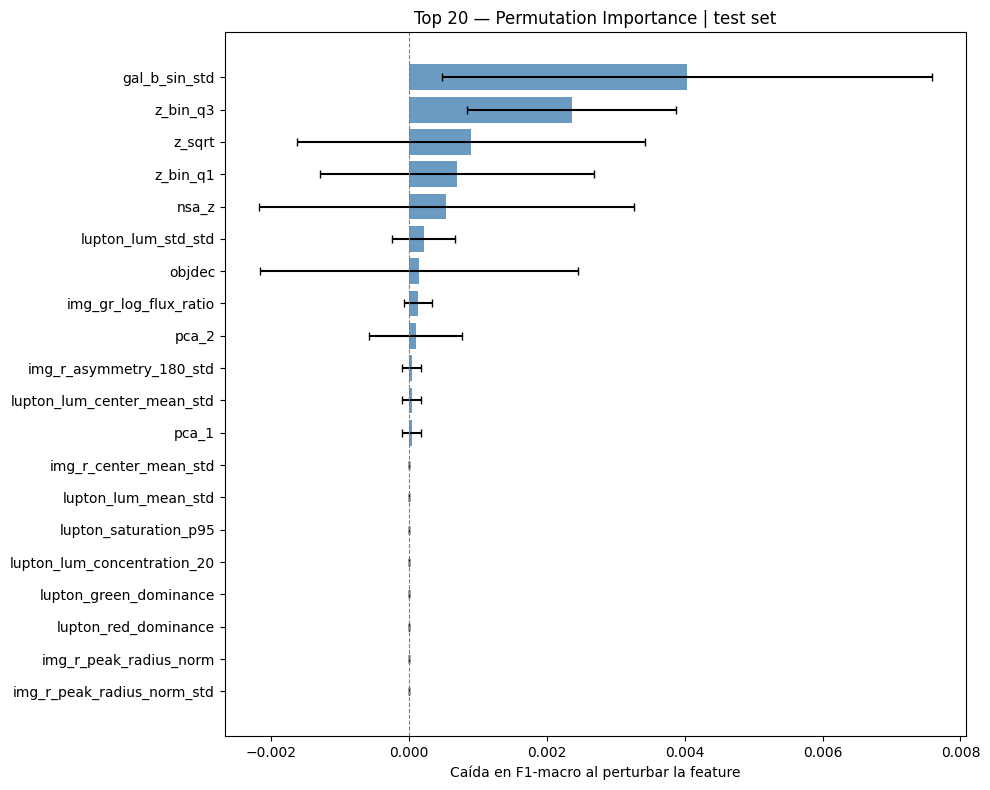

In [13]:
# Plot top 20 features
top20 = perm_df.head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(
    top20['feature'],
    top20['importance_mean'],
    xerr=top20['importance_std'],
    color='steelblue', alpha=0.8, capsize=3
)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_xlabel('Caída en F1-macro al perturbar la feature')
ax.set_title('Top 20 — Permutation Importance | test set')
plt.tight_layout()
plt.show()

In [14]:
low_imp = perm_df[perm_df['importance_mean'] <= 0.001]
print(f'Características con importancia media ≤ 0.001: {len(low_imp)} de {len(perm_df)}')
top_feature = perm_df.iloc[0]
print(f'Mayor media: {top_feature["feature"]} = {top_feature["importance_mean"]:.6f} '
      f'(desviación entre permutaciones: {top_feature["importance_std"]:.6f})')
print('El corte 0.001 es descriptivo; no es un criterio validado de eliminación.')
if top_feature['importance_mean'] <= 0.001:
    print('Todas las medias son pequeñas bajo este corte. El ranking no identifica una contribución individual grande.')
if abs(top_feature['importance_mean']) <= top_feature['importance_std']:
    print('La dispersión de la primera variable es al menos tan grande como su media: interpretar el ranking con cautela.')
print('Revisar redundancia entre originales, versiones estandarizadas y componentes PCA/FA.')
print('Coordenadas y redshift pueden reflejar selección observacional; su relevancia no demuestra causalidad morfológica.')
display(low_imp)

Características con importancia media ≤ 0.001: 84 de 86
Mayor media: gal_b_sin_std = 0.004037 (desviación entre permutaciones: 0.003549)
El corte 0.001 es descriptivo; no es un criterio validado de eliminación.
Revisar redundancia entre originales, versiones estandarizadas y componentes PCA/FA.
Coordenadas y redshift pueden reflejar selección observacional; su relevancia no demuestra causalidad morfológica.


,feature,importance_mean,importance_std
14,z_sqrt,0.000907,0.002519
42,z_bin_q1,0.000704,0.001985
2,nsa_z,0.000544,0.002721
70,lupton_lum_std_std,0.000217,0.000460
1,objdec,0.000147,0.002306
...,...,...,...
4,ra_cos,-0.004906,0.002389
47,ra_cos_std,-0.005463,0.002659
51,gal_l_cos_std,-0.005553,0.003539
46,ra_sin_std,-0.008139,0.004280


### Métrica principal y comparación observada

**F1-macro** promedia el F1 de ambas clases con igual peso. Combina precisión y recall sin permitir que la clase mayoritaria domine el promedio; depende del umbral de clasificación, que se conserva en el valor predeterminado del modelo.

**Average Precision (AP)** resume la curva precisión-recall mediante incrementos de recall; no es necesariamente igual al área trapezoidal bajo esa curva. Permite evaluar el ranking de anillos sin elegir un único umbral. La prevalencia positiva es una referencia de ausencia de discriminación para AP. **ROC-AUC** complementa el análisis, pero no sustituye precisión y recall de la clase minoritaria.

Accuracy se puede reportar, pero no será el criterio principal: predecir siempre la clase mayoritaria puede obtener una cifra elevada sin detectar anillos. No se supone un costo exacto de falsos positivos o negativos sin una definición científica u operativa adicional.

Solo se comparan modelos ejecutados. No se asignan resultados hipotéticos a ResNet o ZooBot.

### Relación entre las métricas y los errores científicos observados

La matriz de confusión contiene **995 verdaderos negativos, 338 falsos positivos, 206 falsos negativos y 143 verdaderos positivos**. Por tanto:

- **Recall de anillos = 143 / 349 = 40.97%:** el modelo deja sin identificar 206 anillos, equivalentes al 59.03% de los positivos de prueba.
- **Precisión de anillos = 143 / 481 = 29.73%:** de 481 candidatos predichos como anillo, 338 son falsos positivos. Una revisión manual tendría una carga relevante.
- **F1-macro = 0.5649:** resume precisión y recall en ambas clases sin ponderarlas por su frecuencia. No equivale a decir que se detectó correctamente el 56.49% de los anillos.

Estos errores hacen pertinente conservar F1-macro como criterio principal del baseline general y reportar siempre precisión y recall de la clase positiva. Si el uso futuro se centra en recuperar candidatos para inspección humana, deberá acordarse el recall requerido y la carga aceptable de falsos positivos antes de seleccionar un umbral en validación.

AP alcanza **0.3074**, frente a **0.2075** del Dummy estratificado, mientras ROC-AUC alcanza **0.6203**, frente a **0.5001**. Son mejoras observadas de ranking y discriminación. Sin intervalos o un contraste apropiado no se afirma significancia estadística. La accuracy de aproximadamente 0.68 es inferior a la del Dummy mayoritario (aproximadamente 0.79), pero este último no recupera ningún anillo: por eso accuracy no decide la elección del modelo.


In [15]:
summary = pd.DataFrame(dummy_results + [{
    'Modelo': 'Random Forest baseline', 'F1-macro': test_f1,
    'ROC-AUC': test_auc, 'AP': test_ap}])
display(summary.round(4))
best_dummy_f1 = max(row['F1-macro'] for row in dummy_results)
best_dummy_ap = max(row['AP'] for row in dummy_results)
print(f'Mejora absoluta F1-macro frente al mejor Dummy: {test_f1-best_dummy_f1:+.4f}')
print(f'Mejora absoluta AP frente al mejor Dummy: {test_ap-best_dummy_ap:+.4f}')
print('Las diferencias observadas no constituyen por sí mismas una prueba de significancia estadística.')

,Modelo,F1-macro,ROC-AUC,AP
0,Dummy stratified,0.5000,0.5001,0.2075
1,Dummy most_frequent,0.4421,0.5000,0.2075
2,Random Forest baseline,0.5649,0.6203,0.3074


Mejora absoluta F1-macro frente al mejor Dummy: +0.0649
Mejora absoluta AP frente al mejor Dummy: +0.0999
Las diferencias observadas no constituyen por sí mismas una prueba de significancia estadística.


### Desempeño mínimo: definición, justificación y verificación

Se distinguen dos preguntas: **¿el modelo mejora descriptivamente a comparadores triviales?** y **¿alcanza el objetivo de calidad adoptado para continuar?** La primera no reemplaza a la segunda.

Se conservan, sin reducirlos después de observar el resultado, los objetivos heredados del notebook original:

| Criterio | Objetivo de referencia | Justificación y límite |
|---|---:|---|
| F1-macro | ≥ 0.70 | Se adopta como una exigencia de calidad equilibrada superior al nivel próximo a 0.50 del comparador estratificado en este conjunto. El valor 0.70 es una decisión de trabajo del proyecto, no una frontera universal ni una garantía de buen recall positivo. |
| ROC-AUC | ≥ 0.80 | Se exige capacidad de ordenar positivos por encima de negativos claramente superior a 0.50, complementando la evaluación a un único umbral de F1. El valor 0.80 es un objetivo de trabajo, no un estándar astronómico validado. |
| Regla conjunta | Cumplir ambos | Evita declarar aceptable un modelo basándose solo en mejora frente a Dummy o solo en capacidad de ranking. |

**Verificación de esta ejecución:** F1-macro **0.5649 < 0.70** y ROC-AUC **0.6203 < 0.80**. Las diferencias respecto a las metas son **−0.1351** y **−0.1797**, respectivamente. **El modelo no alcanza el mínimo de trabajo conservado.** AP y recall aportan contexto, pero no se incorporan retrospectivamente como nuevas reglas para declarar cumplimiento.

Los objetivos permanecen identificados como provisionales porque el material no incluye una validación científica o un acuerdo de costos de error que fundamente sus valores exactos. Esta explicación los hace transparentes, sin convertirlos en requisitos externos. Antes de validar un detector para uso real, el equipo debe definir con el usuario científico precisión/recall o carga de revisión aceptables y reservar una evaluación independiente.

El resultado sí establece una referencia experimental: mejora F1-macro aproximadamente **0.0649** y AP **0.0999** frente al Dummy estratificado. Eso permite comparar desarrollos posteriores, pero no demuestra aceptación operativa ni justifica modificar la meta para aprobar el modelo actual.

In [16]:
# Se conservan los umbrales originales como objetivos PROVISIONALES.
# No son requisitos establecidos por la rúbrica ni umbrales validados para uso científico.
MIN_F1 = 0.70
MIN_AUC = 0.80
f1_ok = test_f1 >= MIN_F1
auc_ok = test_auc >= MIN_AUC
minimum_ok = f1_ok and auc_ok
print('Verificación de objetivos provisionales heredados del notebook original')
print(f'F1-macro ≥ {MIN_F1:.2f}: {"CUMPLE" if f1_ok else "NO CUMPLE"} ({test_f1:.4f})')
print(f'ROC-AUC ≥ {MIN_AUC:.2f}: {"CUMPLE" if auc_ok else "NO CUMPLE"} ({test_auc:.4f})')
print('Estos objetivos exigen discriminación y F1 superiores a comparadores triviales, pero sus valores exactos requieren acuerdo y justificación.')
print('El Equipo 38 debe vincular el mínimo definitivo con precisión/recall requeridos para el uso previsto, antes de una nueva evaluación independiente.')
print('Superar Dummy indica mejora observada; no equivale a cumplir el mínimo ni a estar listo para uso científico.')

Verificación de objetivos provisionales heredados del notebook original
F1-macro ≥ 0.70: NO CUMPLE (0.5649)
ROC-AUC ≥ 0.80: NO CUMPLE (0.6203)
Estos objetivos exigen discriminación y F1 superiores a comparadores triviales, pero sus valores exactos requieren acuerdo y justificación.
El Equipo 38 debe vincular el mínimo definitivo con precisión/recall requeridos para el uso previsto, antes de una nueva evaluación independiente.
Superar Dummy indica mejora observada; no equivale a cumplir el mínimo ni a estar listo para uso científico.


## Conclusión del baseline de anillos — Equipo 38

El Equipo 38 revisó y ejecutó el baseline elaborado originalmente por otro equipo. Después de consolidar una observación repetida, se utilizaron **8,407 galaxias**, distribuidas en **6,725 de entrenamiento** y **1,682 de prueba**, con **86 características** numéricas. Random Forest se conserva como referencia tabular no lineal y se compara con dos Dummy.

El modelo obtiene **F1-macro de 0.5649**, superior al **0.5000** del Dummy estratificado, junto con **ROC-AUC de 0.6203** y **AP de 0.3074**. Las mejoras son descriptivas: esta ejecución no incluye una prueba de significancia. La matriz de confusión evidencia limitaciones prácticas, con **143 anillos detectados de 349** y **338 falsos positivos**.

La brecha de F1-macro entre entrenamiento y prueba es **0.1326**; la validación cruzada obtiene **0.5847 ± 0.0110**, con brecha entrenamiento-validación de **0.1311** al mayor tamaño. Ambos análisis apoyan un diagnóstico de sobreajuste, sin atribuir una causa única. La curva mejora de forma limitada con más muestras dentro del rango evaluado.

La cobertura de imagen es una limitación central: **97.59%** de las galaxias están marcadas sin FITS y las columnas de imagen mostradas presentan esa misma proporción de nulos. Las importancias individuales son pequeñas y encabezan el ranking una transformación de posición galáctica y un intervalo de redshift. Por ello, no se puede afirmar que el modelo haya aprendido una representación visual robusta del anillo ni que las características visuales sean inútiles.

**El baseline no cumple los objetivos de trabajo de F1-macro ≥ 0.70 y ROC-AUC ≥ 0.80.** Su contribución es establecer una referencia reproducible y señalar prioridades de mejora. Los objetivos se mantienen explícitamente como provisionales hasta contar con requisitos científicos que justifiquen sus valores exactos.

### Próximo experimento y límites de la evaluación

1. Auditar rutas, disponibilidad y extracción de imágenes; revisar cobertura por clase y partición antes de concluir que los archivos faltan.
2. Auditar escaladores, PCA, análisis factorial y bins del CSV, para asegurar que se ajustan sin información de prueba y dentro de cada fold cuando se usa validación cruzada.
3. Si se recuperan características de las galaxias actuales, comparar el mismo Random Forest, configuración y partición como experimento pareado descriptivo. Si se seleccionan variables o parámetros a partir de lo aprendido, hacerlo dentro de entrenamiento y usar una evaluación final independiente para sustentar generalización.
4. Evaluar posteriormente un modelo de imagen solo cuando existan imágenes utilizables y etiquetas verificadas, sin anticipar sus puntuaciones.

### Reproducibilidad y entrega

La ejecución guardada no contiene errores y sus celdas de código siguen un orden consecutivo. El entorno reportado es **Python 3.14.5, scikit-learn 1.8.0 y pandas 3.0.3**. También se utilizan NumPy, Matplotlib y Seaborn; sus versiones deben registrarse con las dependencias del repositorio.

Para reproducir: abrir Jupyter o VS Code dentro del repositorio, disponer de `feature_engineering/output/feature_engineered_dataset.csv` o configurar `DATA_PATH_OVERRIDE`, seleccionar el entorno correspondiente, ejecutar **Restart & Run All** y guardar las salidas. Si aparecen inconsistencias de etiquetas, fuentes o particiones en identificadores repetidos, la libreta se detiene para su revisión.

Publicar como **Avance3.38.ipynb** en GitHub con acceso al CSV o a su procedimiento de generación e instrucciones de entorno. Verificar la liga de entrega. La liga no fue suministrada en esta revisión y no se certifica su disponibilidad.

### Referencias metodológicas
- [Random Forest](https://scikit-learn.org/stable/modules/ensemble.html#forest)
- [Permutation importance y características correlacionadas](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html)
- [Prevención de fuga de información y pipelines](https://scikit-learn.org/stable/common_pitfalls.html)
- [Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)
- [Curvas de aprendizaje](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html)

In [17]:
print('Conclusión de la ejecución — revisión del Equipo 38')
print(f'Se utilizaron {len(FEATURE_COLS)} características, {len(y_train)} galaxias de entrenamiento y {len(y_test)} de prueba.')
print(f'F1-macro train/test: {train_f1:.4f}/{test_f1:.4f}; brecha: {gap:.4f}.')
print(diagnosis)
print(f'Validación cruzada al mayor tamaño: {vm[-1]:.4f} ± {vs[-1]:.4f}.')
print(f'ROC-AUC test: {test_auc:.4f}; AP test: {test_ap:.4f}; prevalencia positiva test: {y_test.mean():.4f}.')
print(f'Diferencia F1 frente al mejor Dummy: {test_f1-best_dummy_f1:+.4f}.')
print(f'Objetivos provisionales: {"CUMPLE AMBOS" if minimum_ok else "NO CUMPLE AMBOS"}.')
print(f'{len(low_imp)}/{len(perm_df)} características tienen importancia media ≤ 0.001; esto no determina su eliminación.')
print('La validez final depende también de la auditoría de las transformaciones previas y de la independencia de las particiones.')


Conclusión de la ejecución — revisión del Equipo 38
Se utilizaron 86 características, 6725 galaxias de entrenamiento y 1682 de prueba.
F1-macro train/test: 0.6975/0.5649; brecha: 0.1326.
Indicio de sobreajuste: brecha superior a la alerta heurística de 0.10.
Validación cruzada al mayor tamaño: 0.5847 ± 0.0110.
ROC-AUC test: 0.6203; AP test: 0.3074; prevalencia positiva test: 0.2075.
Diferencia F1 frente al mejor Dummy: +0.0649.
Objetivos provisionales: NO CUMPLE AMBOS.
84/86 características tienen importancia media ≤ 0.001; esto no determina su eliminación.
La validez final depende también de la auditoría de las transformaciones previas y de la independencia de las particiones.
